In [53]:
import torch
import torch.nn as nn
import numpy as np
import os

# --- 0. Checkpoint config ---
CKPT_PATH = 'levelset_pinn.pt'
# For checkpoints that survive runtime restarts, mount Drive and use:
# CKPT_PATH = '/content/drive/MyDrive/wildfire_pinn/levelset_pinn.pt'
FORCE_RETRAIN = False   # set True once when you change the model or training setup

# --- 1. Model architecture (always defined — cheap) ---
class LevelSetPINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1)
        )
    def forward(self, t, x, y):
        return self.net(torch.cat([t, x, y], dim=-1))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
synth_model = LevelSetPINN().to(device)

# --- 2. Load cached weights, or train once ---
if os.path.exists(CKPT_PATH) and not FORCE_RETRAIN:
    synth_model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
    synth_model.eval()
    print(f'Loaded weights from {CKPT_PATH} — training skipped.')
else:
    def get_signed_distance_circle(x, y, r=0.2):
        return torch.sqrt(x**2 + y**2) - r

    optimizer = torch.optim.Adam(synth_model.parameters(), lr=1e-3)

    N_pde = 5000
    t_pde = torch.rand(N_pde, 1, requires_grad=True, device=device) * 0.5
    x_pde = torch.rand(N_pde, 1, requires_grad=True, device=device) * 2.0 - 1.0
    y_pde = torch.rand(N_pde, 1, requires_grad=True, device=device) * 2.0 - 1.0

    N_ic = 1000
    t_ic = torch.zeros(N_ic, 1, device=device)
    x_ic = torch.rand(N_ic, 1, device=device) * 2.0 - 1.0
    y_ic = torch.rand(N_ic, 1, device=device) * 2.0 - 1.0
    u_ic_target = get_signed_distance_circle(x_ic, y_ic)

    for epoch in range(2001):
        optimizer.zero_grad()
        u_ic_pred = synth_model(t_ic, x_ic, y_ic)
        loss_ic = torch.mean((u_ic_pred - u_ic_target)**2)

        u = synth_model(t_pde, x_pde, y_pde)
        grads = torch.autograd.grad(u, [t_pde, x_pde, y_pde], torch.ones_like(u),
                                    create_graph=True, retain_graph=True)
        u_t, u_x, u_y = grads[0], grads[1], grads[2]
        grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)
        loss_pde = torch.mean((u_t + 1.0 * grad_norm)**2)
        loss_eik = torch.mean((grad_norm - 1.0)**2)

        loss = 10.0 * loss_ic + 1.0 * loss_pde + 0.1 * loss_eik
        loss.backward(retain_graph=True)
        optimizer.step()

        if epoch % 500 == 0:
            print(f"Epoch {epoch:4d} | IC Loss: {loss_ic.item():.4f} | PDE Loss: {loss_pde.item():.4f}")

    torch.save(synth_model.state_dict(), CKPT_PATH)
    print(f'Training done — weights saved to {CKPT_PATH}')


RuntimeError: Error(s) in loading state_dict for LevelSetPINN:
	Missing key(s) in state_dict: "net.8.weight", "net.8.bias". 
	size mismatch for net.0.weight: copying a param with shape torch.Size([64, 3]) from checkpoint, the shape in current model is torch.Size([128, 3]).
	size mismatch for net.0.bias: copying a param with shape torch.Size([64]) from checkpoint, the shape in current model is torch.Size([128]).
	size mismatch for net.2.weight: copying a param with shape torch.Size([64, 64]) from checkpoint, the shape in current model is torch.Size([128, 128]).
	size mismatch for net.2.bias: copying a param with shape torch.Size([64]) from checkpoint, the shape in current model is torch.Size([128]).
	size mismatch for net.4.weight: copying a param with shape torch.Size([64, 64]) from checkpoint, the shape in current model is torch.Size([128, 128]).
	size mismatch for net.4.bias: copying a param with shape torch.Size([64]) from checkpoint, the shape in current model is torch.Size([128]).

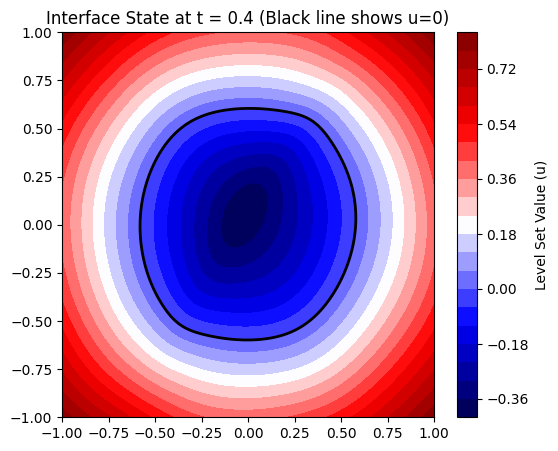

In [2]:
import matplotlib.pyplot as plt

# Generate a grid for plotting at final time t = 0.4
grid_res = 100
x_space = np.linspace(-1, 1, grid_res)
y_space = np.linspace(-1, 1, grid_res)
X, Y = np.meshgrid(x_space, y_space)

# Flatten grid to feed into network
t_eval = torch.full((grid_res * grid_res, 1), 0.4, device=device)
x_eval = torch.tensor(X.flatten()[:, None], dtype=torch.float32, device=device)
y_eval = torch.tensor(Y.flatten()[:, None], dtype=torch.float32, device=device)

with torch.no_grad():
    Z = model(t_eval, x_eval, y_eval).cpu().numpy().reshape(grid_res, grid_res)

# Interpret boundaries
plt.figure(figsize=(6,5))
# Contour level at 0 is the actual interface position
cp = plt.contourf(X, Y, Z, levels=20, cmap='seismic')
plt.colorbar(cp, label="Level Set Value (u)")
# Highlight the zero-level set boundary explicitly
plt.contour(X, Y, Z, levels=[0], colors='black', linewidths=2)
plt.title("Interface State at t = 0.4 (Black line shows u=0)")
plt.show()


### Visualizing the Initial Condition (t=0)
Let's plot the model's prediction at `t=0` to see how well it captures the initial circle.

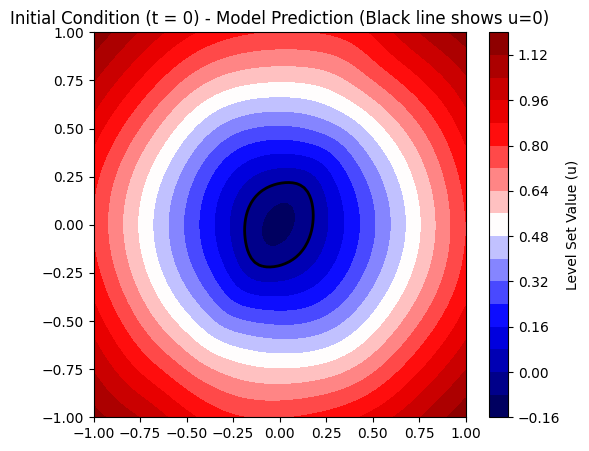

In [3]:
# Generate a grid for plotting at t = 0
grid_res = 100
x_space = np.linspace(-1, 1, grid_res)
y_space = np.linspace(-1, 1, grid_res)
X_0, Y_0 = np.meshgrid(x_space, y_space)

# Flatten grid to feed into network
t_eval_0 = torch.full((grid_res * grid_res, 1), 0.0, device=device)
x_eval_0 = torch.tensor(X_0.flatten()[:, None], dtype=torch.float32, device=device)
y_eval_0 = torch.tensor(Y_0.flatten()[:, None], dtype=torch.float32, device=device)

with torch.no_grad():
    Z_0 = model(t_eval_0, x_eval_0, y_eval_0).cpu().numpy().reshape(grid_res, grid_res)

plt.figure(figsize=(6,5))
cp = plt.contourf(X_0, Y_0, Z_0, levels=20, cmap='seismic')
plt.colorbar(cp, label="Level Set Value (u)")
plt.contour(X_0, Y_0, Z_0, levels=[0], colors='black', linewidths=2)
plt.title("Initial Condition (t = 0) - Model Prediction (Black line shows u=0)")
plt.show()

In [4]:
import numpy as np
from skimage import measure
import torch

def export_interface_mesh(model, target_time, resolution=128):
    """Extracts the exact u=0 boundary as a mesh of vertices and faces."""
    # 1. Create a fine grid evaluation bounding box
    lin = np.linspace(-1.0, 1.0, resolution)
    X, Y = np.meshgrid(lin, lin)

    # 2. Format grid for PyTorch inference
    t_eval = torch.full((resolution * resolution, 1), target_time, dtype=torch.float32)
    x_eval = torch.tensor(X.flatten()[:, None], dtype=torch.float32)
    y_eval = torch.tensor(Y.flatten()[:, None], dtype=torch.float32)

    with torch.no_grad():
        # Get predictions and reshape back to a 2D image array
        Z = model(t_eval, x_eval, y_eval).numpy().reshape(resolution, resolution)

    # 3. Use Marching Squares/Cubes to isolate the exact 0.0 contour line
    contours = measure.find_contours(Z, level=0.0)

    # 4. Map pixel indexes back to physical coordinate space
    physical_contours = []
    for contour in contours:
        real_x = -1.0 + (contour[:, 1] / (resolution - 1)) * 2.0
        real_y = -1.0 + (contour[:, 0] / (resolution - 1)) * 2.0
        physical_contours.append(np.stack([real_x, real_y], axis=1))

    return physical_contours  # List of coordinates tracking the outer boundary


In [5]:
def check_containment(model, time, x_coord, y_coord):
    """Instantly checks if a coordinate is inside, outside, or on the boundary."""
    t_tensor = torch.tensor([[time]], dtype=torch.float32)
    x_tensor = torch.tensor([[x_coord]], dtype=torch.float32)
    y_tensor = torch.tensor([[y_coord]], dtype=torch.float32)

    with torch.no_grad():
        u_val = model(t_tensor, x_tensor, y_tensor).item()

    if u_val < -1e-3:
        return "INSIDE the boundary structure"
    elif u_val > 1e-3:
        return "OUTSIDE the boundary structure"
    else:
        return "EXACTLY ON the interface edge"


In [6]:
def get_surface_normals(model, t, x, y):
    """Calculates the exact direction the shape's boundary is facing."""
    # Ensure gradients can be tracked
    t.requires_grad_(True)
    x.requires_grad_(True)
    y.requires_grad_(True)

    u = model(t, x, y)

    # Take analytical spatial derivatives via PyTorch Autograd
    grads = torch.autograd.grad(u, [x, y], torch.ones_like(u), create_graph=True)
    u_x, u_y = grads[0], grads[1]

    grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)

    # Directional normal vectors pointing outward from the surface
    nx = u_x / grad_norm
    ny = u_y / grad_norm

    return nx.detach(), ny.detach()


In [7]:
def wildfire_pde_residual(model, t, x, y, fuel_spread_rate, wind_x, wind_y):
    u = model(t, x, y)

    # Take derivatives relative to time and space
    grads = torch.autograd.grad(u, [t, x, y], torch.ones_like(u), create_graph=True)
    u_t, u_x, u_y = grads[0], grads[1], grads[2]

    grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)

    # Wildfire level set equation:
    # Fire moves at its base fuel rate (R) + gets pushed along the wind vector
    advection_term = wind_x * u_x + wind_y * u_y
    pde_residual = u_t + advection_term + (fuel_spread_rate * grad_norm)

    return pde_residual


### Defining Wildfire Parameters: Fuel Spread Rate and Wind

To use the `wildfire_pde_residual` function, we need to specify the `fuel_spread_rate` and the `wind_x` and `wind_y` components. These are crucial for modeling how the fire propagates based on the environment.

In [8]:
# Example values for wildfire parameters
# You would typically derive these from real-world data or scenario assumptions.

# Base rate of fire spread due to fuel (e.g., in units per time step)
# A higher value means faster inherent spread.
fuel_spread_rate = 0.05  # Example: 0.05 units/time

# Wind vector components (e.g., in units per time step)
# Positive values indicate wind in the positive x/y direction.
wind_x = 0.02  # Example: wind pushing slightly in positive x
wind_y = 0.03  # Example: wind pushing slightly in positive y

print(f"Fuel Spread Rate: {fuel_spread_rate}")
print(f"Wind X Component: {wind_x}")
print(f"Wind Y Component: {wind_y}")


Fuel Spread Rate: 0.05
Wind X Component: 0.02
Wind Y Component: 0.03


### Processing Fire Perimeter Data

This section will process fire detection data from `firms_raw.csv` to:
1.  Filter for nominal/high confidence detections.
2.  Plot the daily count of detections to understand fire growth/decay.
3.  Generate daily concave hull perimeter polygons using `alphashape`.
4.  Save the resulting polygons to `palisades_perimeters.geojson`.

In [9]:
# Install necessary libraries
!pip install alphashape geopandas

In [10]:
from google.colab import userdata
import pandas as pd, io, requests

MAP_KEY = userdata.get('FIRE_PERIMETER_API_KEY').strip()
BBOX = "-118.70,34.00,-118.42,34.14"  # W,S,E,N

# Archive endpoint caps at 5 days per request -> 5 chunks cover Jan 7-31, 2025
chunks = [("2025-01-07", 5), ("2025-01-12", 5), ("2025-01-17", 5),
          ("2025-01-22", 5), ("2025-01-27", 5)]

dfs = []
for start, days in chunks:
    url = (f"https://firms.modaps.eosdis.nasa.gov/api/area/csv/"
           f"{MAP_KEY}/VIIRS_SNPP_SP/{BBOX}/{days}/{start}")
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    if r.text.startswith("Invalid"):
        raise RuntimeError(r.text[:200])
    dfs.append(pd.read_csv(io.StringIO(r.text)))
    print(start, "->", len(dfs[-1]), "detections")

df = pd.concat(dfs, ignore_index=True).drop_duplicates(
    subset=["latitude", "longitude", "acq_date", "acq_time"])
df.to_csv("firms_raw.csv", index=False)
print("unique detections:", len(df),
      "| range:", df["acq_date"].min(), "->", df["acq_date"].max())


2025-01-07 -> 1102 detections
2025-01-12 -> 5 detections
2025-01-17 -> 0 detections
2025-01-22 -> 0 detections
2025-01-27 -> 0 detections
unique detections: 1107 | range: 2025-01-07 -> 2025-01-12


/tmp/ipykernel_25469/4267786152.py:22: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(dfs, ignore_index=True).drop_duplicates(


In [11]:
import pandas as pd

df_firms = pd.read_csv('firms_raw.csv')
df_firms['acq_date'] = pd.to_datetime(df_firms['acq_date'])

print('confidence values:', df_firms['confidence'].value_counts().to_dict())
# VIIRS codes are single letters: l / n / h. Old filter kept only 'h'.
df_filtered = df_firms[df_firms['confidence'].isin(['n', 'h'])].copy()
print(f"kept {len(df_filtered)} / {len(df_firms)} detections (nominal + high)")

# sub-daily key: one perimeter per satellite overpass, not per day
df_filtered['overpass'] = (df_filtered['acq_date'].dt.strftime('%Y-%m-%d')
                           + '_' + df_filtered['acq_time'].astype(str).str.zfill(4))


confidence values: {'n': 909, 'h': 147, 'l': 51}
kept 1056 / 1107 detections (nominal + high)


       overpass   n
2025-01-07_2104  42
2025-01-08_0926 369
2025-01-08_2045 118
2025-01-09_0907 100
2025-01-09_1047  58
2025-01-09_2026  50
2025-01-10_0848  41
2025-01-10_1028  67
2025-01-10_2008  24
2025-01-10_2148  17
2025-01-11_1010  90
2025-01-11_1949  32
2025-01-11_2129  43
2025-01-12_0951   5


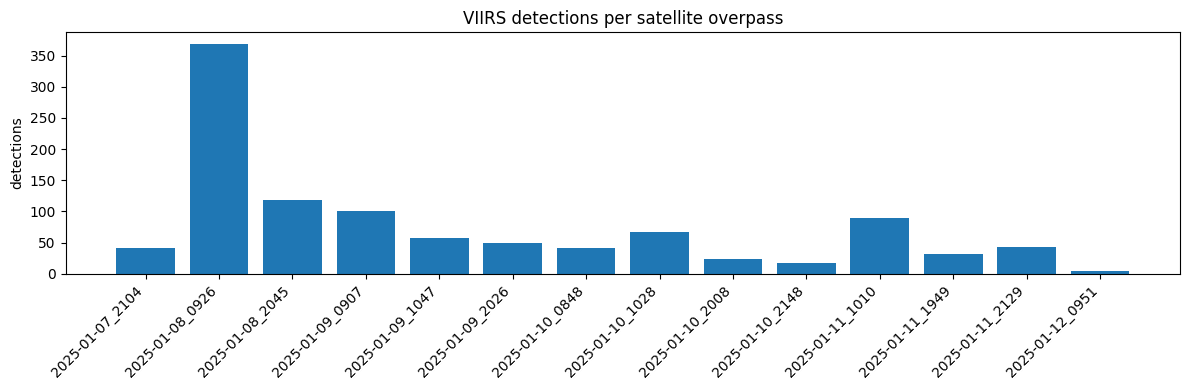

In [12]:
import matplotlib.pyplot as plt

per_pass = df_filtered.groupby('overpass').size().reset_index(name='n').sort_values('overpass')
print(per_pass.to_string(index=False))

plt.figure(figsize=(12, 4))
plt.bar(range(len(per_pass)), per_pass['n'])
plt.xticks(range(len(per_pass)), per_pass['overpass'], rotation=45, ha='right')
plt.ylabel('detections')
plt.title('VIIRS detections per satellite overpass')
plt.tight_layout()
plt.show()


In [13]:
import geopandas as gpd
import pandas as pd

perimeters_gdf = gpd.read_file('palisades_perimeters.geojson')
perimeters_gdf['acq_date'] = pd.to_datetime(perimeters_gdf['acq_date'])
perimeters_gdf = perimeters_gdf.sort_values(['acq_date', 'acq_time']).reset_index(drop=True)
perimeters_gdf['overpass'] = (perimeters_gdf['acq_date'].dt.strftime('%Y-%m-%d')
                              + '_' + perimeters_gdf['acq_time'].astype(str))
print(perimeters_gdf[['overpass', 'n_points']].to_string(index=False))

# provisional: first half of overpasses train, rest held-out — confirm from the chart
k = max(1, len(perimeters_gdf) // 2)
train_overpasses = perimeters_gdf['overpass'].iloc[:k].tolist()
heldout_overpasses = perimeters_gdf['overpass'].iloc[k:].tolist()
print('train:', train_overpasses)
print('held-out:', heldout_overpasses)


       overpass  n_points
2025-01-07_2104        42
2025-01-08_0926       369
2025-01-08_2045       118
2025-01-09_0907       100
2025-01-09_1047        58
2025-01-09_2026        50
2025-01-10_0848        41
2025-01-10_1028        67
2025-01-10_2008        24
2025-01-10_2148        17
2025-01-11_1010        90
2025-01-11_1949        32
2025-01-11_2129        43
2025-01-12_0951         5
train: ['2025-01-07_2104', '2025-01-08_0926', '2025-01-08_2045', '2025-01-09_0907', '2025-01-09_1047', '2025-01-09_2026', '2025-01-10_0848']
held-out: ['2025-01-10_1028', '2025-01-10_2008', '2025-01-10_2148', '2025-01-11_1010', '2025-01-11_1949', '2025-01-11_2129', '2025-01-12_0951']


### Adapting the PINN for Real Fire Perimeters

To 'constrain the PINN on days 1-3' and then predict fire spread, we need to adapt the existing `LevelSetPINN` setup. Currently, the PINN is trained to model the evolution of a simple circle as its initial condition.

For a real wildfire scenario, the most critical change is to **redefine the PINN's initial condition** (at `t=0`) based on the actual fire perimeter from your first training day (e.g., `2025-01-07`). This involves:

1.  **Converting the initial fire perimeter polygon into a Signed Distance Function (SDF).** An SDF gives, for any point in space, its shortest distance to the boundary, with the sign indicating whether the point is inside (negative) or outside (positive).
2.  **Modifying the PINN's training loop** (`ESZIXhHTQ_OR`) to use this new SDF as its `u_ic_target` (initial condition target) for `t=0` points, instead of `get_signed_distance_circle`.
3.  **Incorporating the wildfire PDE residual:** Ensure the `wildfire_pde_residual` function (`uIwvOLnJY7mK`) with your defined `fuel_spread_rate`, `wind_x`, and `wind_y` parameters is used in the PINN's PDE loss component during training.

Let's first create a helper function to generate a Signed Distance Function (SDF) from a given Shapely polygon. This SDF will then be used as the initial condition for your PINN.

In [14]:
from shapely.geometry import Polygon, MultiPolygon, Point
from scipy.ndimage import distance_transform_edt
import numpy as np

def create_sdf_from_polygon(polygon, x_grid, y_grid):
    """
    Generates a Signed Distance Function (SDF) for a given Shapely polygon
    over a specified 2D grid.

    Args:
        polygon (Polygon or MultiPolygon): The Shapely polygon(s) representing the fire perimeter.
        x_grid (np.array): 1D array of x-coordinates for the grid.
        y_grid (np.array): 1D array of y-coordinates for the grid.

    Returns:
        np.array: A 2D array (len(y_grid), len(x_grid)) representing the SDF.
                  Negative values are inside the polygon, positive outside.
    """
    # Create a meshgrid from the 1D grid arrays
    X, Y = np.meshgrid(x_grid, y_grid)
    points = np.stack([X.ravel(), Y.ravel()], axis=-1)

    # Determine which points are inside the polygon
    # Use a binary mask for the polygon
    mask = np.array([polygon.contains(Point(p)) for p in points]).reshape(X.shape)

    # Calculate Euclidean distance transform
    distance = distance_transform_edt(~mask) # Distance to nearest False (outside)
    distance[mask] = -distance_transform_edt(mask)[mask] # Distance to nearest True (inside), make negative

    return distance

print("Helper function `create_sdf_from_polygon` defined.")

Helper function `create_sdf_from_polygon` defined.


In [15]:
from shapely.prepared import prep
from shapely.geometry import Point
from scipy.ndimage import distance_transform_edt
import numpy as np

PIXEL_M = 90.0  # stack resolution; EDT returns pixel units

def create_sdf_from_polygon(polygon, x_grid, y_grid):
    """Signed distance in meters, negative inside. Polygon must share x_grid/y_grid's CRS."""
    X, Y = np.meshgrid(x_grid, y_grid)
    flat = np.stack([X.ravel(), Y.ravel()], axis=-1)
    prep_poly = prep(polygon)
    mask = np.array([prep_poly.contains(Point(px, py)) for px, py in flat]).reshape(X.shape)
    sdf = distance_transform_edt(~mask) * PIXEL_M
    sdf[mask] = -distance_transform_edt(mask)[mask] * PIXEL_M
    return sdf


### Extracting the Initial Fire Perimeter and Generating its SDF

Now, let's extract the perimeter for the first training day (Day 1) and use the `create_sdf_from_polygon` function to generate its Signed Distance Function (SDF). This SDF will represent `u(t=0, x, y)` for your PINN.

SDF shape: (178, 290) | min: -994 m, max: 15898 m


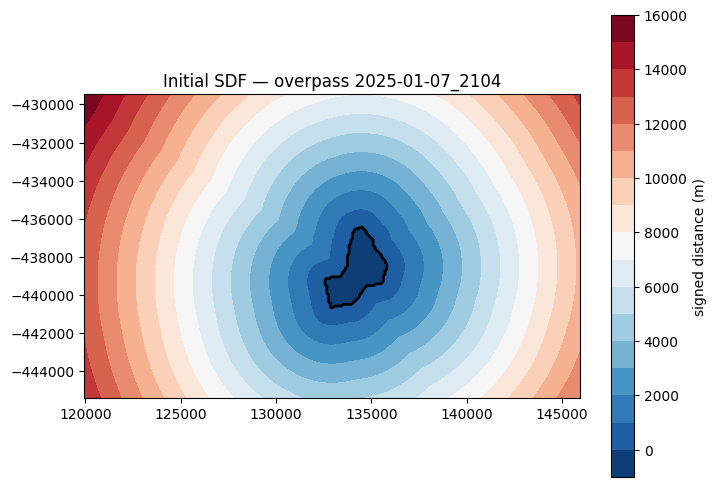

In [16]:
import xarray as xr
import matplotlib.pyplot as plt

stack = xr.open_dataset('palisades_stack.nc')
x_grid, y_grid = stack['x'].values, stack['y'].values  # EPSG:3310, meters

perim_3310 = perimeters_gdf.to_crs('EPSG:3310')
first = perim_3310.iloc[0]
initial_sdf = create_sdf_from_polygon(first['geometry'], x_grid, y_grid)

print('SDF shape:', initial_sdf.shape,
      '| min: %.0f m, max: %.0f m' % (initial_sdf.min(), initial_sdf.max()))
assert initial_sdf.min() < 0 < initial_sdf.max(), 'no zero contour — CRS mismatch!'

plt.figure(figsize=(8, 6))
plt.contourf(x_grid, y_grid, initial_sdf, levels=20, cmap='RdBu_r')
plt.colorbar(label='signed distance (m)')
plt.contour(x_grid, y_grid, initial_sdf, levels=[0], colors='black', linewidths=2)
plt.title(f"Initial SDF — overpass {first['overpass']}")
plt.gca().set_aspect('equal', adjustable='box')
plt.show()


In [17]:
export_interface_mesh(model, target_time=10)

[]

### Demonstrating `check_containment`
Let's test the `check_containment` function with a specific point at `t=0.4`.

In [18]:
# Example usage of check_containment
test_time = 0.4
test_x_inside = 0.1
test_y_inside = 0.1
test_x_outside = 0.8
test_y_outside = 0.8

status_inside = check_containment(model, test_time, test_x_inside, test_y_inside)
status_outside = check_containment(model, test_time, test_x_outside, test_y_outside)

print(f"Point ({test_x_inside}, {test_y_inside}) at t={test_time}: {status_inside}")
print(f"Point ({test_x_outside}, {test_y_outside}) at t={test_time}: {status_outside}")

Point (0.1, 0.1) at t=0.4: INSIDE the boundary structure
Point (0.8, 0.8) at t=0.4: OUTSIDE the boundary structure


### Demonstrating `get_surface_normals`
Let's visualize the surface normals at a few points along the interface at `t=0.4`.

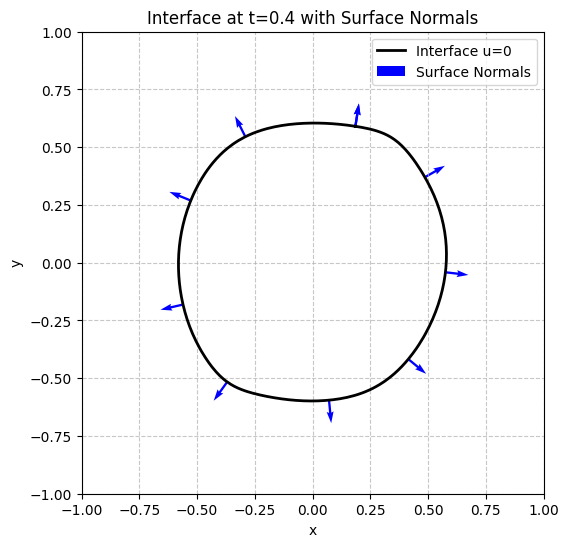

In [19]:
import matplotlib.pyplot as plt

# Get the interface points for visualization of normals
interface_contours = export_interface_mesh(model, target_time=0.4)

plt.figure(figsize=(7,6))

# Plot the interface
if interface_contours:
    for contour in interface_contours:
        plt.plot(contour[:, 0], contour[:, 1], 'k-', linewidth=2, label='Interface u=0')

# Sample points on the interface to plot normals
# We'll take a few points from the first contour if it exists
if interface_contours and len(interface_contours[0]) > 5:
    # Sample a few points for plotting normals
    sample_indices = np.linspace(0, len(interface_contours[0]) - 1, 10, dtype=int)
    sample_points = torch.tensor(interface_contours[0][sample_indices], dtype=torch.float32)

    t_normals = torch.full((sample_points.shape[0], 1), 0.4, device=device, requires_grad=True)
    x_normals = sample_points[:, 0:1].to(device).clone().detach().requires_grad_(True)
    y_normals = sample_points[:, 1:2].to(device).clone().detach().requires_grad_(True)

    nx, ny = get_surface_normals(model, t_normals, x_normals, y_normals)

    # Plot normals
    plt.quiver(x_normals.cpu().detach().numpy(), y_normals.cpu().detach().numpy(),
               nx.cpu().detach().numpy(), ny.cpu().detach().numpy(),
               color='blue', scale=20, width=0.005, label='Surface Normals')

plt.title("Interface at t=0.4 with Surface Normals")
plt.xlabel("x"); plt.ylabel("y")
plt.grid(True, linestyle='--', alpha=0.7)
plt.gca().set_aspect('equal', adjustable='box')
plt.xlim([-1, 1]); plt.ylim([-1, 1])
plt.legend()
plt.show()

### Animating the Interface Evolution
Let's see how the interface changes over time using `export_interface_mesh`.

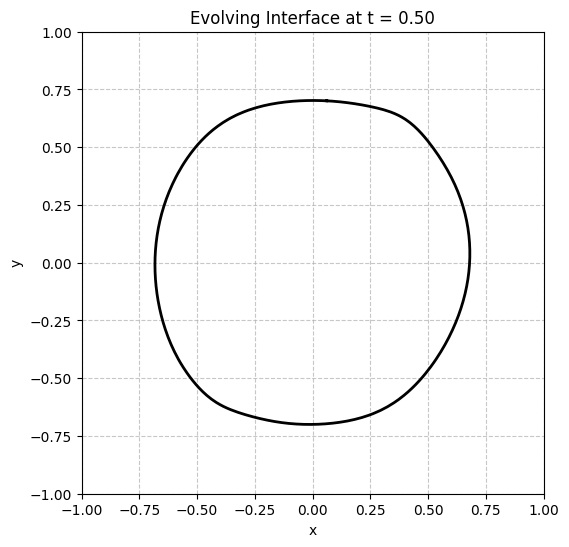

In [20]:
import matplotlib.animation as animation
from IPython.display import HTML

# Define the time steps for the animation
time_steps = np.linspace(0, 0.5, 20) # 20 frames from t=0 to t=0.5

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim([-1, 1])
ax.set_ylim([-1, 1])
ax.set_title("Evolving Interface")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_aspect('equal', adjustable='box')
ax.grid(True, linestyle='--', alpha=0.7)

line, = ax.plot([], [], 'k-', lw=2)

def animate(i):
    current_time = time_steps[i]
    ax.set_title(f"Evolving Interface at t = {current_time:.2f}")
    contours = export_interface_mesh(model, target_time=current_time)
    if contours:
        # Assuming we are interested in the largest contour if multiple are found
        largest_contour = max(contours, key=len)
        line.set_data(largest_contour[:, 0], largest_contour[:, 1])
    else:
        line.set_data([], []) # Clear data if no contour is found
    return line,

anim = animation.FuncAnimation(fig, animate, frames=len(time_steps), interval=200, blit=True)

# Display the animation
HTML(anim.to_jshtml())

### Getting Terrain Data with `elevation`

To download terrain data, we'll use the `elevation` Python package. This package relies on `GDAL`, so we'll first install `gdal-bin` on the system, then install the `elevation` library itself. Finally, we'll use `elevation.clip` to download a specific region.

In [21]:
# Install GDAL development libraries, which are a dependency for 'elevation'
!sudo apt-get update
!sudo apt-get install -y gdal-bin

Hit:1 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Get:3 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:6 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Fetched 3,917 B in 2s (2,294 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
gdal-bin is already the newest version (3.8.4+dfsg-3ubuntu3).
0 upgraded, 0 newly installed, 0 to remove and 26 not upgraded.


In [22]:
# Install the elevation Python package
!pip install elevation

In [23]:
import requests

W, S, E, N = -118.70, 34.00, -118.42, 34.14  # Palisades bbox

base = ("https://lfps.usgs.gov/arcgis/rest/services/"
        "Landfire_LF2023/LF2023_FBFM40_CONUS/ImageServer/exportImage")
params = {
    "bbox": f"{W},{S},{E},{N}", "bboxSR": 4326, "imageSR": 4326,
    "size": "1039,520",          # native 30 m pixels over this bbox
    "format": "tiff", "pixelType": "U8", "noData": 0, "f": "json",
}
href = requests.get(base, params=params).json()["href"]

with requests.get(href, stream=True) as r, open("palisades_fbfm40.tif", "wb") as f:
    for chunk in r.iter_content(1 << 20):
        f.write(chunk)
print("saved palisades_fbfm40.tif")


saved palisades_fbfm40.tif


In [24]:
import rasterio
with rasterio.open("palisades_fbfm40.tif") as src:
    a = src.read(1)
print(a.shape, a.min(), a.max())  # expect ~(520, 1039), values 91..204


(520, 1039) 91 189


### Downloading and Processing GridMET Data

This section will download daily [gridMET](https://www.climatologylab.org/gridmet.html) NetCDF data for January 2025, clip it to the specified bounding box, and save it to a single NetCDF file `gridmet_jan2025.nc`. We'll focus on wind speed (`vs`), wind direction (`th`), maximum temperature (`tmmx`), minimum relative humidity (`rmin`), and 100-hour dead fuel moisture (`fm100`).

In [25]:
# Install necessary libraries for NetCDF handling and geospatial operations
!pip install xarray netCDF4 rioxarray

In [26]:
import requests, xarray as xr

W, S, E, N = -118.70, 34.00, -118.42, 34.14
BASE = "http://thredds.northwestknowledge.net:8080/thredds/ncss/MET"
VARS = {
    "vs":    "wind_speed",
    "th":    "wind_from_direction",
    "tmmx":  "air_temperature",
    "rmin":  "relative_humidity",
    "fm100": "dead_fuel_moisture_100hr",
}

import os

subs = {}
for short, std in VARS.items():
    url = (f"{BASE}/{short}/{short}_2025.nc?var={std}"
           f"&north={N}&south={S}&west={W}&east={E}"
           "&time_start=2025-01-07T00:00:00Z&time_end=2025-01-31T00:00:00Z"
           "&accept=netCDF")
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    path = f"gridmet_{short}_jan2025.nc"
    open(path, "wb").write(r.content)
    with xr.open_dataset(path) as ds:          # closes the handle on exit
        da = ds[std].rename(short).load()
    subs[short] = da
    print(short, dict(da.sizes))

out = "gridmet_jan2025.nc"
if os.path.exists(out):                        # clear the stale file first
    os.chmod(out, 0o644)
    os.remove(out)
xr.Dataset(subs).to_netcdf(out)
print("saved", out)


vs {'day': 25, 'lat': 5, 'lon': 7}
th {'day': 25, 'lat': 5, 'lon': 7}
tmmx {'day': 25, 'lat': 5, 'lon': 7}
rmin {'day': 25, 'lat': 5, 'lon': 7}
fm100 {'day': 25, 'lat': 5, 'lon': 7}
saved gridmet_jan2025.nc


SDF shape: (178, 290) | min: -994 m, max: 15898 m


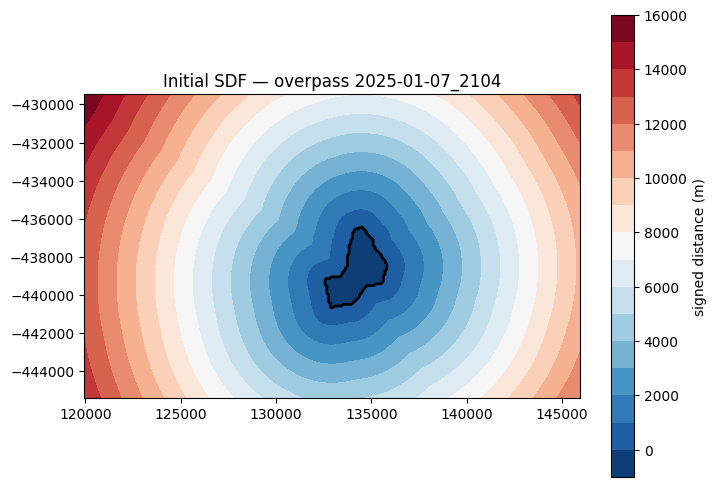

In [27]:
import xarray as xr
import matplotlib.pyplot as plt

stack = xr.open_dataset('palisades_stack.nc')
x_grid, y_grid = stack['x'].values, stack['y'].values  # EPSG:3310, meters

perim_3310 = perimeters_gdf.to_crs('EPSG:3310')
first = perim_3310.iloc[0]
initial_sdf = create_sdf_from_polygon(first['geometry'], x_grid, y_grid)

print('SDF shape:', initial_sdf.shape,
      '| min: %.0f m, max: %.0f m' % (initial_sdf.min(), initial_sdf.max()))
assert initial_sdf.min() < 0 < initial_sdf.max(), 'no zero contour — CRS mismatch!'

plt.figure(figsize=(8, 6))
plt.contourf(x_grid, y_grid, initial_sdf, levels=20, cmap='RdBu_r')
plt.colorbar(label='signed distance (m)')
plt.contour(x_grid, y_grid, initial_sdf, levels=[0], colors='black', linewidths=2)
plt.title(f"Initial SDF — overpass {first['overpass']}")
plt.gca().set_aspect('equal', adjustable='box')
plt.show()


In [28]:
# Install necessary libraries if not already installed
!pip install rioxarray scipy

In [29]:
import os
for f in ["srtm.tif", "palisades_fbfm40.tif", "firms_raw.csv", "gridmet_jan2025.nc"]:
    print(("OK  " if os.path.exists(f) else "MISS"), f)


MISS srtm.tif
OK   palisades_fbfm40.tif
OK   firms_raw.csv
OK   gridmet_jan2025.nc


In [30]:
import requests

W, S, E, N = -118.70, 34.00, -118.42, 34.14

def lanfire_download(service, out):
    base = (f"https://lfps.usgs.gov/arcgis/rest/services/Landfire_Topo/"
            f"{service}/ImageServer/exportImage")
    params = {"bbox": f"{W},{S},{E},{N}", "bboxSR": 4326, "imageSR": 4326,
              "size": "1039,520", "format": "tiff", "f": "json"}
    r = requests.get(base, params=params, timeout=120)
    r.raise_for_status()
    href = r.json().get("href")
    if not href:
        raise RuntimeError(str(r.json())[:300])
    with requests.get(href, stream=True, timeout=300) as d, open(out, "wb") as f:
        for chunk in d.iter_content(1 << 20):
            f.write(chunk)
    print("saved", out)

lanfire_download("LF2020_Elev_CONUS", "palisades_elev.tif")
lanfire_download("LF2020_SlpD_CONUS", "palisades_sloped.tif")


saved palisades_elev.tif
saved palisades_sloped.tif


In [33]:
import os
import xarray as xr

def force_save(ds, path):
    """to_netcdf that survives stale/locked target files."""
    tmp = path + '.tmp'
    if os.path.exists(tmp):
        os.remove(tmp)
    ds.to_netcdf(tmp)                 # fresh inode, none of the old file's baggage
    if os.path.exists(path):
        try:
            os.chmod(path, 0o644)     # in case it's read-only
        except Exception as e:
            print('chmod note:', e)
    os.replace(tmp, path)             # atomic swap; only needs write perm on /content
    print('saved', path)

force_save(palisades_stack, '/content/palisades_stack.nc')


saved /content/palisades_stack.nc


### Reprojecting and Stacking Geospatial Data

Now we will process the raw geospatial files. We will:
- Define the target Coordinate Reference System (CRS) as `EPSG:3310` (California Albers) and a target resolution of 90 meters.
- Load `srtm.tif` (elevation) and reproject it to the target CRS and resolution.
- Calculate the slope from the reprojected elevation data.
- Load `palisades_fbfm40.tif` (fuel model) and `gridmet_jan2025.nc` (wind and fuel moisture data).
- Reproject and resample these datasets to precisely match the grid of the reprojected elevation data.
- Combine all processed layers into a single `xarray.Dataset`.
- Save the combined dataset as `palisades_stack.nc`.
- Visualize all layers to confirm alignment.

In [34]:
import xarray as xr
import rioxarray  # noqa: F401  (registers the .rio accessor)
import numpy as np
import os
from rasterio.enums import Resampling

TARGET_CRS = 'EPSG:3310'      # California Albers
TARGET_RESOLUTION = 90.0      # meters
W, S, E, N = -118.70, 34.00, -118.42, 34.14

# --- 1. Elevation: LANDFIRE (continuous -> bilinear OK) ---
print('Processing palisades_elev.tif...')
dem_rio = rioxarray.open_rasterio('palisades_elev.tif', chunks={'x': 256, 'y': 256})
if dem_rio.rio.crs is None:
    dem_rio.rio.write_crs('EPSG:4326', inplace=True)
dem_reprojected = (dem_rio.rio.reproject(TARGET_CRS, resolution=TARGET_RESOLUTION)
                   .squeeze('band', drop=True).rename('elevation_m'))
print('elev:', dem_reprojected.shape)

# --- 2. Slope (degrees, precomputed by LANDFIRE) ---
print('Processing palisades_sloped.tif...')
slp_rio = rioxarray.open_rasterio('palisades_sloped.tif', chunks={'x': 256, 'y': 256})
if slp_rio.rio.crs is None:
    slp_rio.rio.write_crs('EPSG:4326', inplace=True)
slope_reprojected = (slp_rio.rio.reproject_match(dem_reprojected)
                     .squeeze('band', drop=True).rename('slope_deg'))
print('slope:', slope_reprojected.shape)

# --- 3. Fuel model (CATEGORICAL -> nearest neighbor, never bilinear) ---
print('Processing palisades_fbfm40.tif...')
fuel_rio = rioxarray.open_rasterio('palisades_fbfm40.tif', chunks={'x': 256, 'y': 256})
if fuel_rio.rio.crs is None:
    fuel_rio.rio.write_crs('EPSG:4326', inplace=True)
fuel_reprojected = (fuel_rio.rio.reproject_match(dem_reprojected, resampling=Resampling.nearest)
                    .squeeze('band', drop=True).rename('fuel_model'))
vals = fuel_reprojected.values
print('fuel:', fuel_reprojected.shape, '| codes:', np.unique(vals[~np.isnan(vals)]).astype(int))

# --- 4. gridMET (continuous -> bilinear OK) ---
print('Processing gridmet_jan2025.nc...')
gridmet_ds = xr.open_dataset('gridmet_jan2025.nc')
if gridmet_ds.rio.crs is None:
    gridmet_ds.rio.write_crs('EPSG:4326', inplace=True)
gridmet_selected = gridmet_ds[['vs', 'th', 'fm100']].rename(
    {'vs': 'wind_speed', 'th': 'wind_dir', 'fm100': 'fuel_moisture'})
gridmet_reprojected = gridmet_selected.rio.reproject_match(dem_reprojected)
print('gridmet:', dict(gridmet_reprojected.sizes))

# --- 5. Stack & save ---
palisades_stack = xr.Dataset({
    'elevation_m': dem_reprojected,
    'slope_deg': slope_reprojected,
    'fuel_model': fuel_reprojected,
    **gridmet_reprojected.data_vars,
})
palisades_stack.to_netcdf('palisades_stack.nc')
print('Saved palisades_stack.nc')
palisades_stack


Processing palisades_elev.tif...
elev: (178, 290)
Processing palisades_sloped.tif...
slope: (178, 290)
Processing palisades_fbfm40.tif...
fuel: (178, 290) | codes: [  0  91  93  98  99 101 102 103 121 122 123 141 142 144 145 147 161 163
 165 181 182 183 184 185 186 188 189]
Processing gridmet_jan2025.nc...
gridmet: {'day': 25, 'x': 290, 'y': 178}
Saved palisades_stack.nc


<xarray.Dataset> Size: 31MB
Dimensions:        (x: 290, y: 178, day: 25)
Coordinates:
  * x              (x) float64 2kB 1.199e+05 1.2e+05 ... 1.458e+05 1.459e+05
  * y              (y) float64 1kB -4.295e+05 -4.296e+05 ... -4.454e+05
  * day            (day) datetime64[ns] 200B 2025-01-07 ... 2025-01-31
    spatial_ref    int64 8B 0
    crs            int64 8B 0
Data variables:
    elevation_m    (y, x) int16 103kB -32768 -32768 -32768 ... -32768 -32768
    slope_deg      (y, x) int16 103kB -32768 -32768 -32768 ... -32768 -32768
    fuel_model     (y, x) uint8 52kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    wind_speed     (day, y, x) float64 10MB 6.2 6.2 6.2 6.2 ... 1.6 1.6 1.6 1.6
    wind_dir       (day, y, x) float64 10MB 24.0 24.0 24.0 ... 321.0 321.0 321.0
    fuel_moisture  (day, y, x) float64 10MB 7.4 7.4 7.4 7.4 ... 12.2 12.2 12.2

In [35]:
# --- 1. Elevation + slope from LANDFIRE (both continuous: bilinear is correct) ---
dem_rio = rioxarray.open_rasterio('palisades_elev.tif', chunks={'x': 256, 'y': 256})
if dem_rio.rio.crs is None:
    dem_rio.rio.write_crs('EPSG:4326', inplace=True)
dem_reprojected = (dem_rio.rio.reproject(TARGET_CRS, resolution=TARGET_RESOLUTION)
                   .squeeze('band', drop=True).rename('elevation_m'))

slp_rio = rioxarray.open_rasterio('palisades_sloped.tif', chunks={'x': 256, 'y': 256})
if slp_rio.rio.crs is None:
    slp_rio.rio.write_crs('EPSG:4326', inplace=True)
slope_reprojected = (slp_rio.rio.reproject_match(dem_reprojected)
                     .squeeze('band', drop=True).rename('slope_deg'))
print("elev:", dem_reprojected.shape, "| slope:", slope_reprojected.shape)


elev: (178, 290) | slope: (178, 290)


In [36]:
for v in ['elevation_m', 'slope_deg']:
    a = palisades_stack[v].values
    valid = a[a != -32768]
    print(v, '| valid fraction:', round(len(valid)/a.size, 3),
          '| range:', valid.min(), '-', valid.max())


elevation_m | valid fraction: 0.961 | range: 0 - 848
slope_deg | valid fraction: 0.961 | range: 0 - 55


       overpass   n
2025-01-07_2104  42
2025-01-08_0926 369
2025-01-08_2045 118
2025-01-09_0907 100
2025-01-09_1047  58
2025-01-09_2026  50
2025-01-10_0848  41
2025-01-10_1028  67
2025-01-10_2008  24
2025-01-10_2148  17
2025-01-11_1010  90
2025-01-11_1949  32
2025-01-11_2129  43
2025-01-12_0951   5


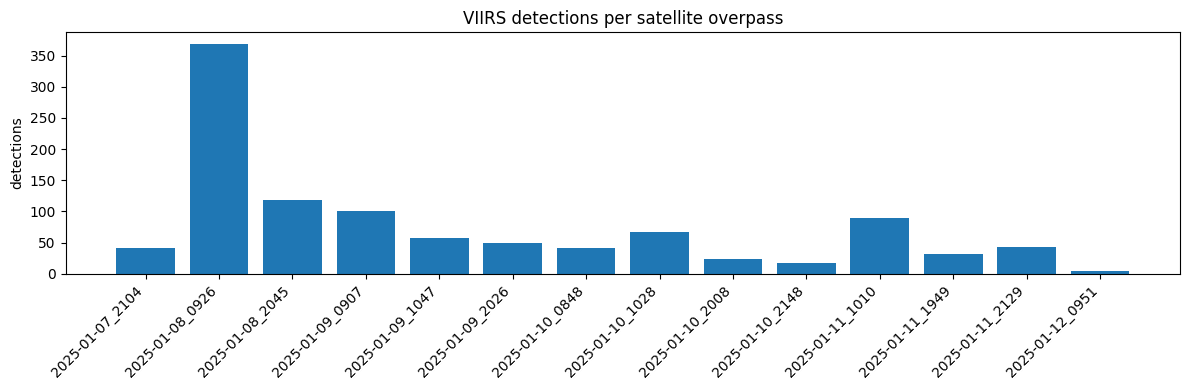

In [37]:
import matplotlib.pyplot as plt

per_pass = df_filtered.groupby('overpass').size().reset_index(name='n').sort_values('overpass')
print(per_pass.to_string(index=False))

plt.figure(figsize=(12, 4))
plt.bar(range(len(per_pass)), per_pass['n'])
plt.xticks(range(len(per_pass)), per_pass['overpass'], rotation=45, ha='right')
plt.ylabel('detections')
plt.title('VIIRS detections per satellite overpass')
plt.tight_layout()
plt.show()


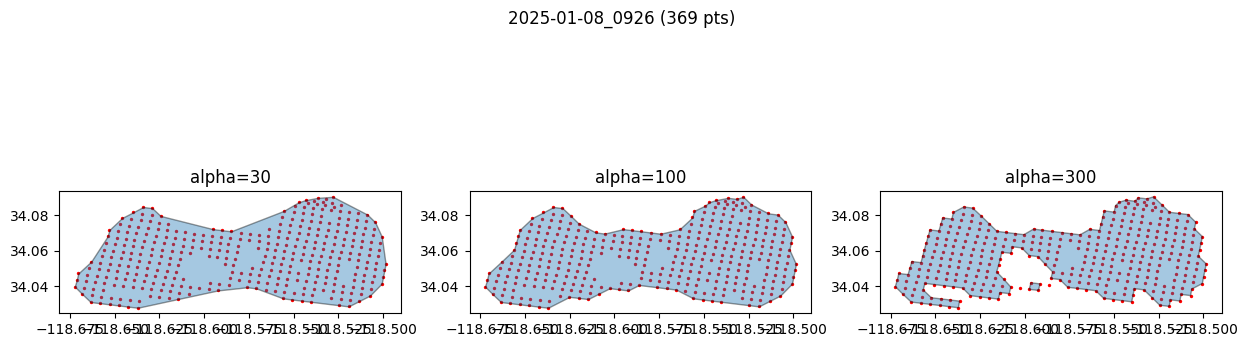

In [38]:
import alphashape, geopandas as gpd
import matplotlib.pyplot as plt

biggest = df_filtered.groupby('overpass').size().idxmax()
pts = df_filtered[df_filtered['overpass'] == biggest][['longitude', 'latitude']].values

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, a in zip(axes, [30, 100, 300]):
    shape = alphashape.alphashape(pts, a)
    ax.scatter(pts[:, 0], pts[:, 1], s=2, c='red')
    if not shape.is_empty:
        gpd.GeoSeries([shape]).plot(ax=ax, alpha=0.4, edgecolor='black')
    ax.set_title(f'alpha={a}')
    ax.set_aspect('equal')
plt.suptitle(f'{biggest} ({len(pts)} pts)')
plt.show()


In [39]:
import geopandas as gpd
from shapely.geometry import MultiPoint
from shapely.ops import unary_union
import alphashape
import pandas as pd

ALPHA = 100.0      # from the sweep above; carving radius ~1/ALPHA degrees
MIN_POINTS = 4

rows, skipped = [], []
for overpass, group in df_filtered.groupby('overpass'):
    pts = group[['longitude', 'latitude']].values
    if len(pts) < MIN_POINTS:
        skipped.append((overpass, len(pts), 'too few points'))
        continue
    try:
        shape = alphashape.alphashape(pts, ALPHA)
    except Exception as e:
        skipped.append((overpass, len(pts), f'alphashape failed: {e}'))
        continue
    if shape.is_empty:
        skipped.append((overpass, len(pts), 'empty shape'))
        continue
    date_str, time_str = overpass.split('_')
    rows.append({'acq_date': date_str, 'acq_time': time_str,
                 'n_points': len(pts), 'geometry': unary_union(shape)})

print('built:', len(rows), '| skipped:', len(skipped))
for s in skipped:
    print('  skipped:', s)

gdf_perimeters = gpd.GeoDataFrame(rows, crs='EPSG:4326')
gdf_perimeters.to_file('palisades_perimeters.geojson', driver='GeoJSON')
print('saved palisades_perimeters.geojson')


built: 14 | skipped: 0
saved palisades_perimeters.geojson


### Visualizing Stacked Geospatial Layers

Below are plots of the reprojected and resampled geospatial layers to confirm their alignment and content. We will visualize:
- Elevation (in meters)
- Slope (in degrees)
- Fuel Model (FBFM40 codes)
- Wind Speed
- Wind Direction
- Fuel Moisture (100-hr)

All plots should show the same spatial extent and resolution, indicating successful alignment.

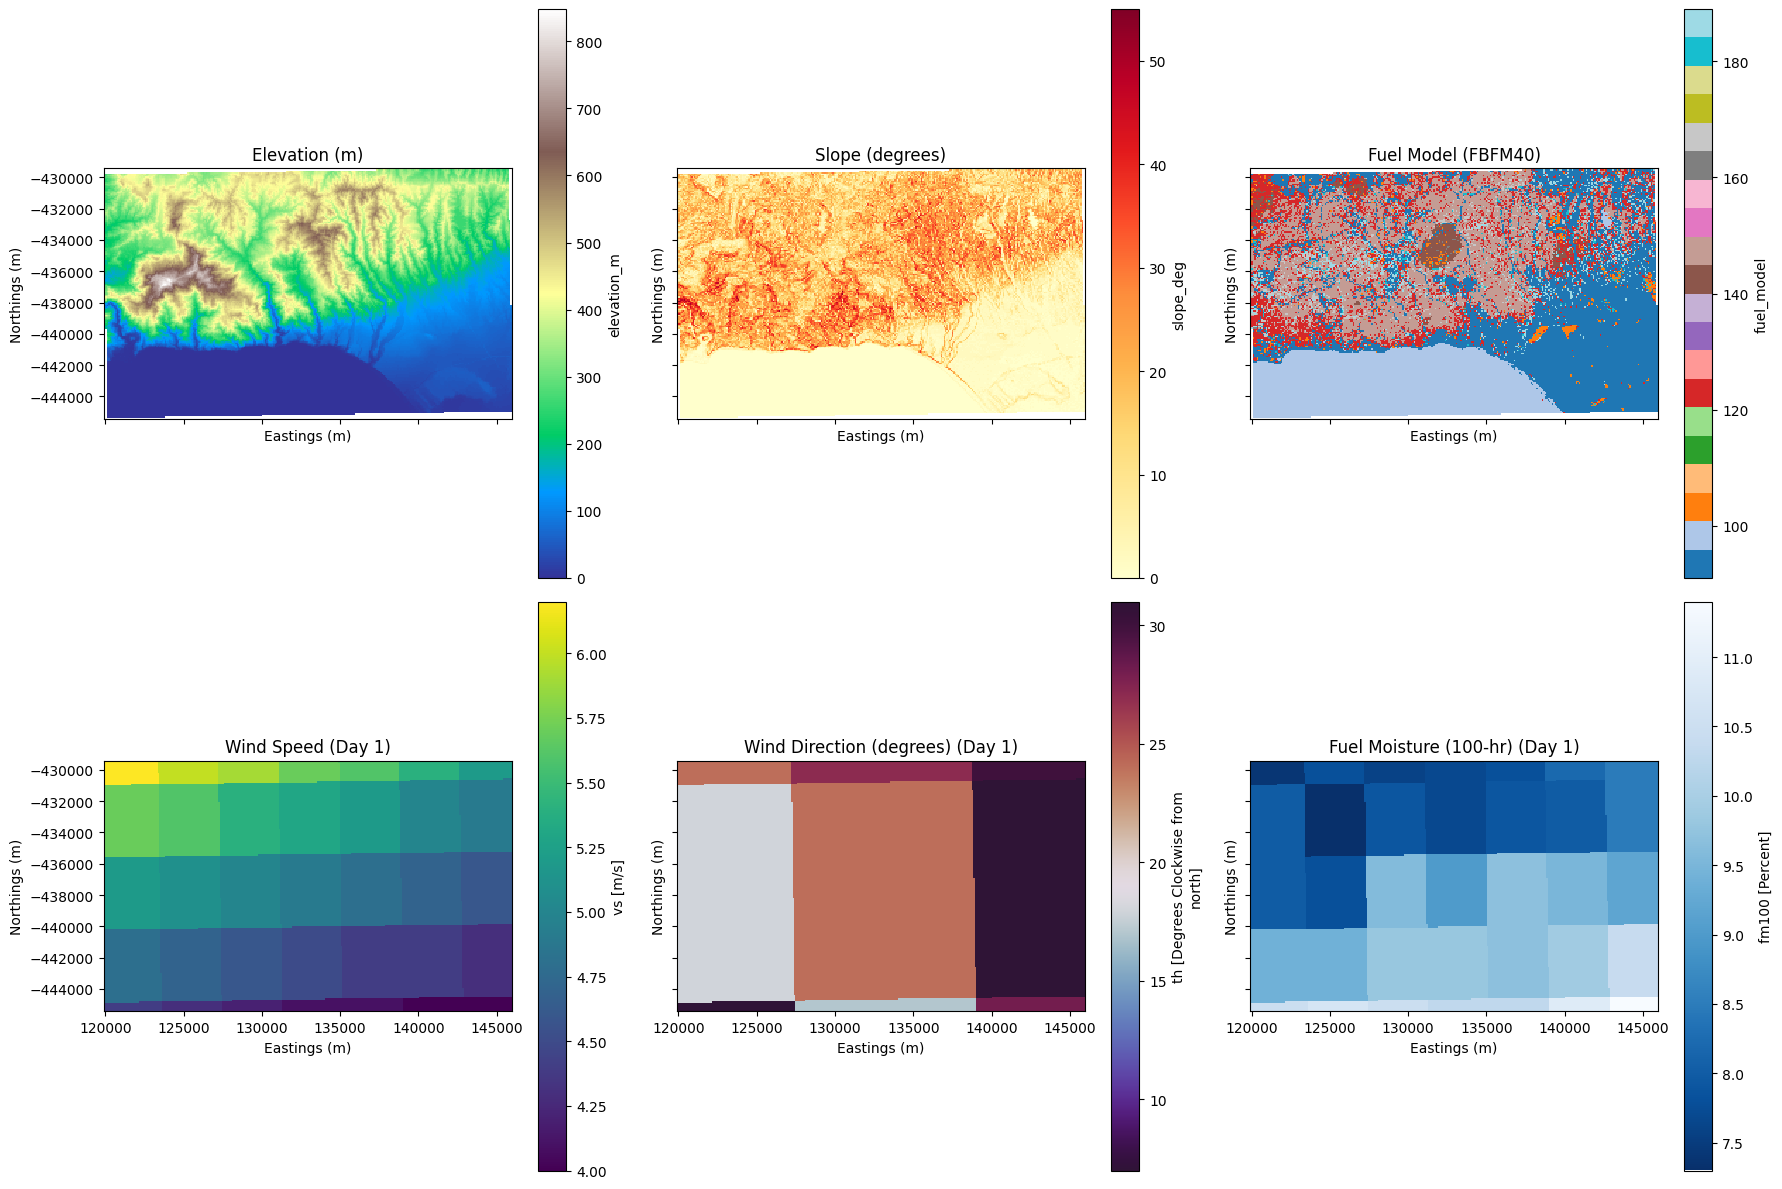

In [40]:
import matplotlib.pyplot as plt

# Load the stacked dataset for plotting
stacked_data = xr.open_dataset('palisades_stack.nc')

fig, axes = plt.subplots(ncols=3, nrows=2, figsize=(18, 12), sharex=True, sharey=True)
axes = axes.flatten()

# Define the variables to plot and their titles/colormaps
plot_vars = [
    ('elevation_m', 'Elevation (m)', 'terrain'),
    ('slope_deg', 'Slope (degrees)', 'YlOrRd'),
    ('fuel_model', 'Fuel Model (FBFM40)', 'tab20'), # Discrete colormap for fuel models
    ('wind_speed', 'Wind Speed', 'viridis'),
    ('wind_dir', 'Wind Direction (degrees)', 'twilight_shifted'),
    ('fuel_moisture', 'Fuel Moisture (100-hr)', 'Blues_r')
]

for i, (var_name, title, cmap) in enumerate(plot_vars):
    if var_name in stacked_data:
        ax = axes[i]
        # For time-varying data, plot the first timestep
        if 'day' in stacked_data[var_name].dims:
            data_to_plot = stacked_data[var_name].isel(day=0)
            title += ' (Day 1)'
        else:
            data_to_plot = stacked_data[var_name]

        data_to_plot.plot.imshow(ax=ax, cmap=cmap, add_colorbar=True)
        ax.set_title(title)
        ax.set_xlabel('Eastings (m)')
        ax.set_ylabel('Northings (m)')
        ax.set_aspect('equal', adjustable='box')
    else:
        axes[i].set_title(f'{var_name} not found')

plt.tight_layout()
plt.show()


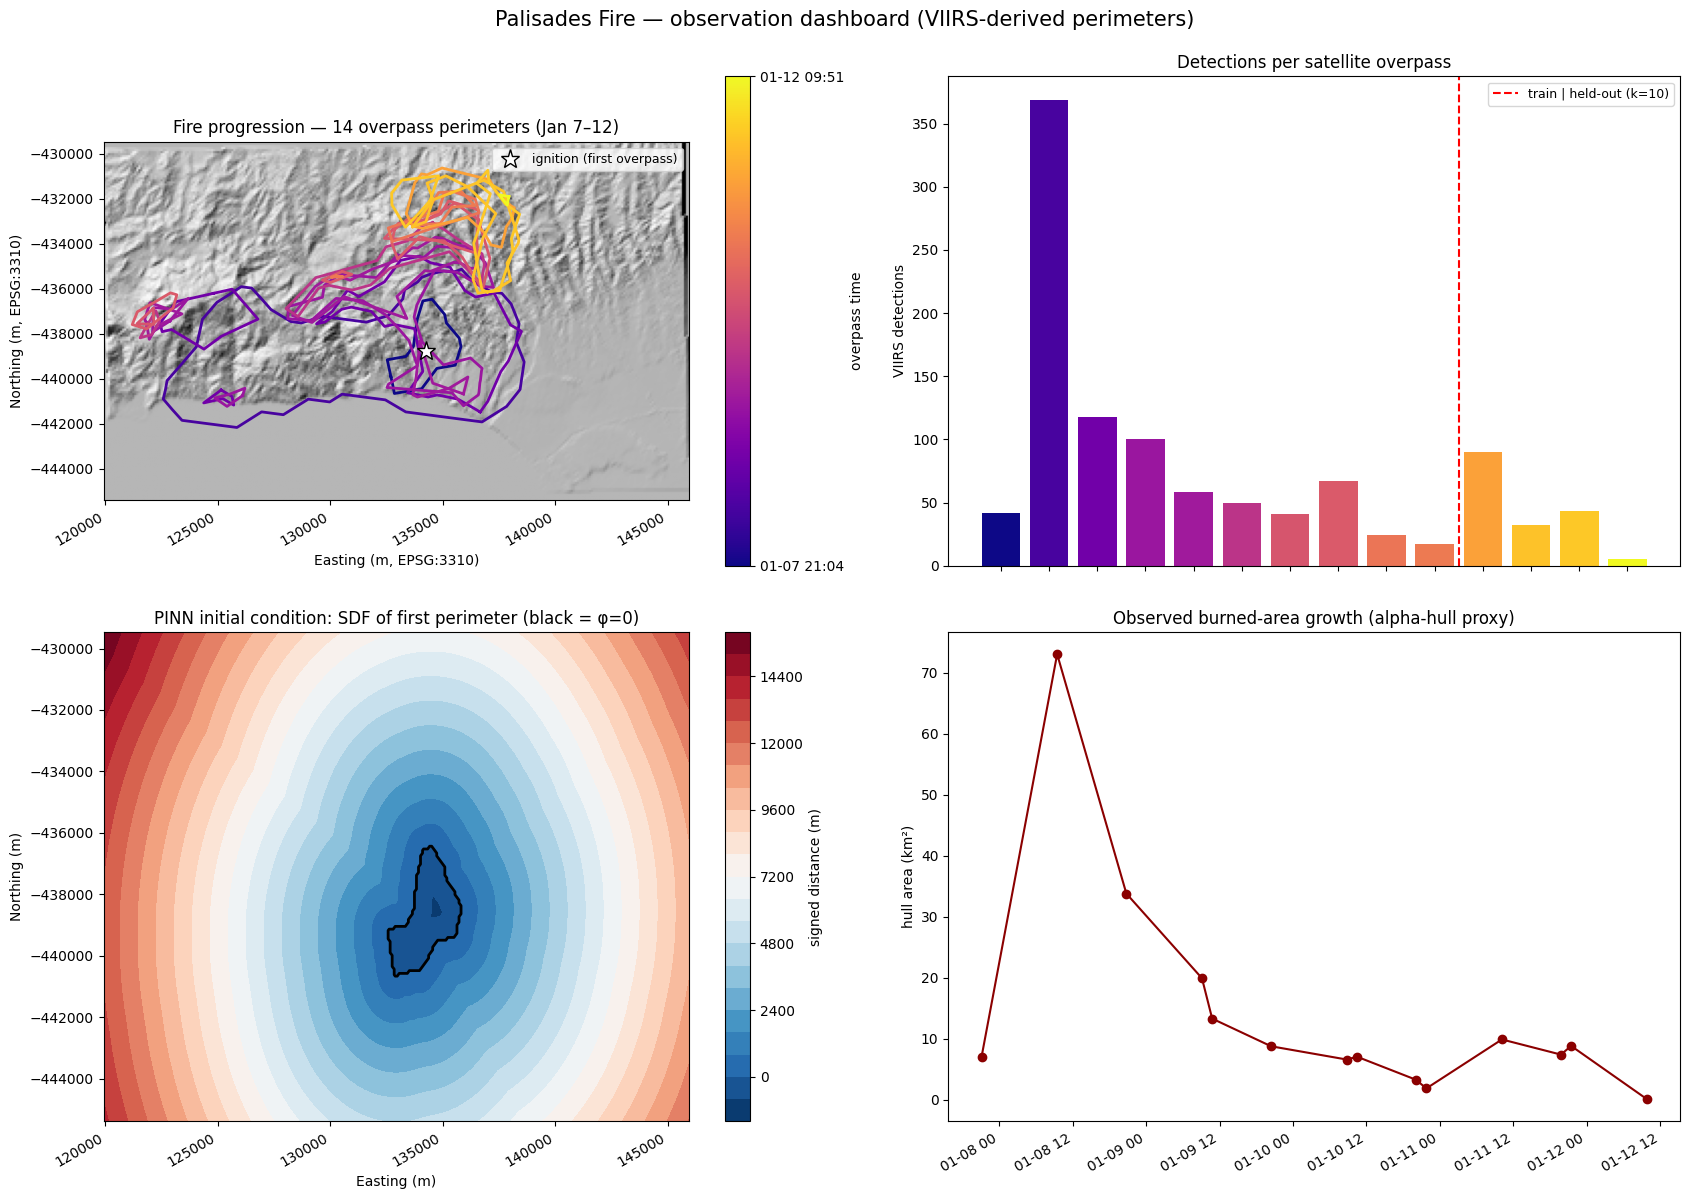

In [43]:
# ============================================================
# FINAL DASHBOARD — the whole fire story in one figure.
# Reads palisades_stack.nc + palisades_perimeters.geojson
# ============================================================
import matplotlib.pyplot as plt
import numpy as np, pandas as pd, xarray as xr, geopandas as gpd

stack = xr.open_dataset('palisades_stack.nc')
x, y = stack['x'].values, stack['y'].values
elev = np.nan_to_num(stack['elevation_m'].values, nan=0.0)

perims = gpd.read_file('palisades_perimeters.geojson')
perims['acq_date'] = pd.to_datetime(perims['acq_date'])
perims = perims.sort_values(['acq_date', 'acq_time']).reset_index(drop=True)
tstr = perims['acq_time'].astype(str).str.zfill(4)
perims['dt'] = (perims['acq_date']
                + pd.to_timedelta(tstr.str[:2].astype(int), unit='h')
                + pd.to_timedelta(tstr.str[2:].astype(int), unit='m'))
p3310 = perims.to_crs('EPSG:3310')
tnorm = (perims['dt'] - perims['dt'].min()) / (perims['dt'].max() - perims['dt'].min())
cmap = plt.cm.plasma

dy, dx = np.gradient(elev, 90.0)                      # simple hillshade
az, alt = np.deg2rad(315), np.deg2rad(45)
_s = np.pi/2 - np.arctan(np.hypot(dx, dy)); _a = np.arctan2(-dx, dy)
hs = np.clip(np.sin(alt)*np.sin(_s) + np.cos(alt)*np.cos(_s)*np.cos(az - _a), 0, 1)

fig, ax = plt.subplots(2, 2, figsize=(17, 12))

a = ax[0, 0]                                          # A — perimeter stack on terrain
a.imshow(hs, cmap='gray', extent=[x.min(), x.max(), y.min(), y.max()], origin='upper')
for i, row in p3310.iterrows():
    geom = row['geometry']
    parts = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
    for p in parts:
        xs, ys = p.exterior.xy
        a.plot(xs, ys, color=cmap(tnorm.iloc[i]), lw=2)

ig = p3310.iloc[0].geometry.centroid
a.plot(ig.x, ig.y, '*', color='white', ms=14, mec='black', label='ignition (first overpass)')
sm = plt.cm.ScalarMappable(cmap=cmap)
cbar = fig.colorbar(sm, ax=a, label='overpass time')
cbar.set_ticks([0, 1])
cbar.set_ticklabels([perims['dt'].min().strftime('%m-%d %H:%M'),
                     perims['dt'].max().strftime('%m-%d %H:%M')])
a.set_title(f'Fire progression — {len(p3310)} overpass perimeters (Jan 7–12)')
a.set_xlabel('Easting (m, EPSG:3310)'); a.set_ylabel('Northing (m, EPSG:3310)')
a.legend(loc='upper right', fontsize=9)

b = ax[0, 1]                                          # B — detections per overpass
b.bar(range(len(perims)), perims['n_points'], color=cmap(tnorm))
b.set_xticks(range(len(perims)))
b.set_xticklabels([d.strftime('%m-%d %H:%M') for d in perims['dt']],
                  rotation=45, ha='right', fontsize=8)
b.set_ylabel('VIIRS detections'); b.set_title('Detections per satellite overpass')
b.axvline(9.5, color='red', ls='--', label='train | held-out (k=10)')
b.legend(fontsize=9)

c = ax[1, 0]                                          # C — PINN initial condition
sdf0 = create_sdf_from_polygon(p3310.iloc[0]['geometry'], x, y)
cf = c.contourf(x, y, sdf0, levels=24, cmap='RdBu_r')
c.contour(x, y, sdf0, levels=[0], colors='black', linewidths=2)
fig.colorbar(cf, ax=c, label='signed distance (m)')
c.set_title('PINN initial condition: SDF of first perimeter (black = φ=0)')
c.set_xlabel('Easting (m)'); c.set_ylabel('Northing (m)')

d = ax[1, 1]                                          # D — area growth
d.plot(perims['dt'], p3310.area.values / 1e6, 'o-', color='darkred')
d.set_ylabel('hull area (km²)')
d.set_title('Observed burned-area growth (alpha-hull proxy)')
fig.autofmt_xdate(rotation=30)

plt.suptitle('Palisades Fire — observation dashboard (VIIRS-derived perimeters)',
             fontsize=15, y=0.995)
plt.tight_layout(); plt.show()
stack.close()


In [44]:
# Data inventory — what palisades_stack.nc holds and why each variable stays
import xarray as xr
stack = xr.open_dataset('palisades_stack.nc')
roles = {
    'elevation_m': 'plot context (slope already derived)',
    'slope_deg': 'REQUIRED — slope correction in Rothermel R',
    'fuel_model': 'REQUIRED — FBFM40 lookup -> base spread rate',
    'wind_speed': 'REQUIRED — wind correction in R',
    'wind_from_direction': 'REQUIRED — wind vector direction in R',
    'dead_fuel_moisture_100hr': 'REQUIRED — moisture damping in R',
    'air_temperature': 'supporting — diagnostics / live fuel moisture later',
    'relative_humidity': 'supporting — diagnostics / live fuel moisture later',
}
print(f"{'variable':28s}{'shape':22s}role")
for v in stack.data_vars:
    print(f"{v:28s}{str(stack[v].shape):22s}{roles.get(v, '?')}")
print('\ndims:', dict(stack.sizes),
      '| ~%.1f MB' % (sum(stack[v].nbytes for v in stack.data_vars) / 1e6))
stack.close()


variable                    shape                 role
spatial_ref                 ()                    ?
elevation_m                 (178, 290)            plot context (slope already derived)
slope_deg                   (178, 290)            REQUIRED — slope correction in Rothermel R
fuel_model                  (178, 290)            REQUIRED — FBFM40 lookup -> base spread rate
crs                         ()                    ?
wind_speed                  (25, 178, 290)        REQUIRED — wind correction in R
wind_dir                    (25, 178, 290)        ?
fuel_moisture               (25, 178, 290)        ?

dims: {'y': 178, 'x': 290, 'day': 25} | ~32.2 MB


In [45]:
# ============================================================
# REBUILD perimeters with per-overpass outlier trimming.
# Identical to the previous builder (ALPHA=100 hull in degrees,
# saved EPSG:4326) except each overpass is trimmed in EPSG:3310
# meters first: points whose 3rd-nearest-neighbor distance exceeds
# median + 4*MAD are dropped. Never trims below MIN_POINTS.
# Overwrites palisades_perimeters.geojson.
# After running: re-run the train-split cell and the dashboard.
# ============================================================
import numpy as np, pandas as pd, geopandas as gpd
import alphashape
from shapely.geometry import Point
from shapely.ops import unary_union
from scipy.spatial.distance import cdist

ALPHA = 100.0
MIN_POINTS = 4

df = pd.read_csv('firms_raw.csv')
df['acq_date'] = pd.to_datetime(df['acq_date'])
df_filtered = df[df['confidence'].isin(['n', 'h'])].copy()
df_filtered['overpass'] = (df_filtered['acq_date'].dt.strftime('%Y-%m-%d') + '_' +
                           df_filtered['acq_time'].astype(str).str.zfill(4))

def trim_outliers(lonlat):
    gs = gpd.GeoSeries([Point(lo, la) for lo, la in lonlat],
                       crs='EPSG:4326').to_crs('EPSG:3310')
    xy = np.column_stack([gs.x.values, gs.y.values])
    n = len(xy)
    if n <= MIN_POINTS + 1:
        return np.ones(n, dtype=bool)
    d3 = np.sort(cdist(xy, xy), axis=1)[:, 3]
    med = np.median(d3)
    mad = np.median(np.abs(d3 - med)) + 1e-9
    keep = d3 <= med + 4 * mad
    return keep if keep.sum() >= MIN_POINTS else np.ones(n, dtype=bool)

rows, skipped = [], []
for overpass, group in df_filtered.groupby('overpass'):
    pts = group[['longitude', 'latitude']].values
    keep = trim_outliers(pts)
    ptsk = pts[keep]
    if len(ptsk) < MIN_POINTS:
        skipped.append((overpass, len(ptsk), 'too few points after trim'))
        continue
    try:
        shape = alphashape.alphashape(ptsk, ALPHA)
    except Exception as e:
        skipped.append((overpass, len(ptsk), f'alphashape failed: {e}'))
        continue
    if shape.is_empty:
        skipped.append((overpass, len(ptsk), 'empty shape'))
        continue
    date_str, time_str = overpass.split('_')
    rows.append({'overpass': overpass, 'acq_date': date_str, 'acq_time': time_str,
                 'n_points': len(ptsk), 'n_raw': len(pts), 'geometry': unary_union(shape)})

print('built:', len(rows), '| skipped:', len(skipped))
for s in skipped:
    print('  skipped:', s)
gdf_perimeters = gpd.GeoDataFrame(rows, crs='EPSG:4326')
gdf_perimeters.to_file('palisades_perimeters.geojson', driver='GeoJSON')
print('saved palisades_perimeters.geojson')
print(gdf_perimeters[['overpass', 'n_raw', 'n_points']].to_string(index=False))


built: 14 | skipped: 0
saved palisades_perimeters.geojson
       overpass  n_raw  n_points
2025-01-07_2104     42        42
2025-01-08_0926    369       316
2025-01-08_2045    118       106
2025-01-09_0907    100        80
2025-01-09_1047     58        50
2025-01-09_2026     50        45
2025-01-10_0848     41        32
2025-01-10_1028     67        62
2025-01-10_2008     24        19
2025-01-10_2148     17        17
2025-01-11_1010     90        83
2025-01-11_1949     32        28
2025-01-11_2129     43        35
2025-01-12_0951      5         5


burnable fraction: 0.481
day 0: median R=0.182 m/s | mean=0.163 | max=0.341
day 1: median R=0.236 m/s | mean=0.212 | max=0.432
day 4: median R=0.141 m/s | mean=0.126 | max=0.256
sanity: Jan-8 blowup moved the front ~km in ~12 h -> expect ~0.05-0.2 m/s.
If median R is far outside that band, adjust C_REF.


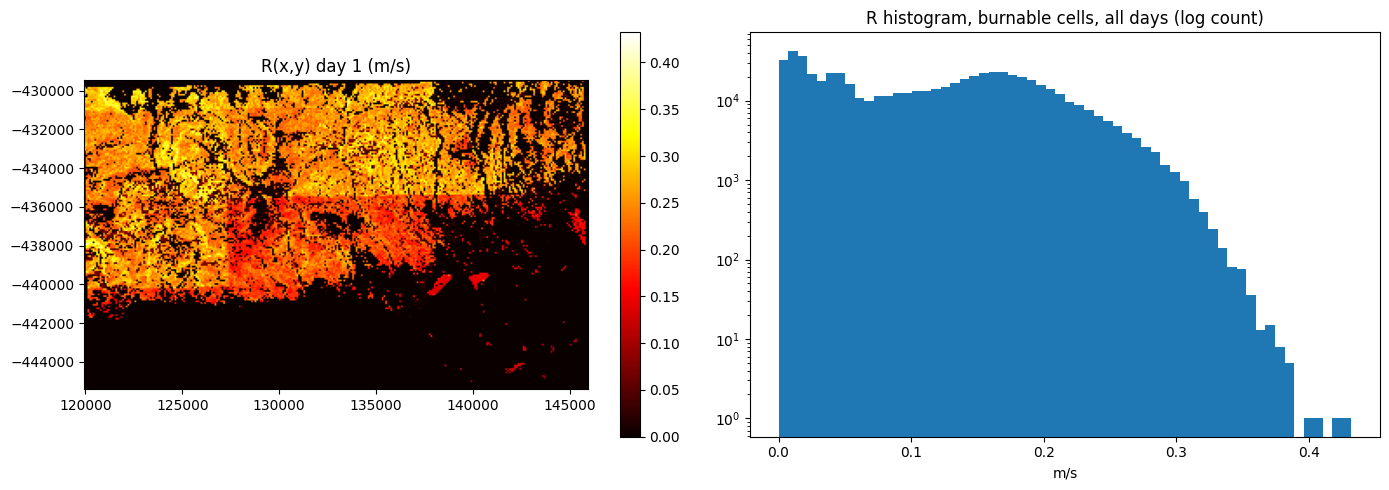

saved palisades_R.nc (25, 178, 290)


In [48]:
# ============================================================
# R(x,y,t): first-order spread-rate field (m/s) -> palisades_R.nc
# R = C_REF * r_rel[fuel] * W(U) * S(slope) * M(moisture)
# r_rel tiers from published ROS adjective bands (RMRS-GTR-153
#   Table 5 via NWCG S-290; D2L2 moisture, 5 mi/h midflame, 0 slope):
#   grass/shrub (101-103,121-123,141-147) -> High band      r_rel=1.0
#   timber understory (161,163,165)       -> Low-Mod band   r_rel=0.2
#   timber litter (181-189)               -> VLow-Low band  r_rel=0.07
# C_REF = 0.177 m/s = 31.6 chains/h, geometric midpoint of the High
#   band. THE single calibration knob (see sanity check below).
# W(U) = (1+C_W*U)/(1+C_W*U_REF), U_REF=2.237 m/s (5 mi/h),
#   C_W=0.5 [calibration].  S = 1+C_S*tan(slope), C_S=1.0 [calibration].
# M = clip(1-fm100/Mx,0,1); Mx per fuel model SOURCED from Scott &
#   Burgan (2005) via firestarter-io/fuelmodels (not invented).
# Non-burnable (0,91,93,98,99) -> R=0. Wind DIRECTION is not in this
# scalar field; the residual applies the PoC-validated downwind factor.
# Full Rothermel: deferred scope, as agreed.
# ============================================================
import numpy as np, xarray as xr
import matplotlib.pyplot as plt

stack = xr.open_dataset('palisades_stack.nc')
fuel_raw = stack['fuel_model'].values
fuel = np.where(np.isnan(fuel_raw), 0, fuel_raw).astype(int)  # NaN (ocean) -> 0 = nodata = non-burnable
slope = np.deg2rad(stack['slope_deg'].values)    # (y, x)
U     = stack['wind_speed'].values               # (day, y, x), m/s
fm    = stack['fuel_moisture'].values            # (day, y, x), %

MX = {101:15, 102:15, 103:30, 121:15, 122:15, 123:15,        # sourced, see header
      141:15, 142:15, 144:30, 145:15, 147:15,
      161:20, 163:30, 165:25,
      181:30, 182:25, 183:20, 184:25, 185:25, 186:25, 188:35, 189:35}
R_REL = {}
for c in [101,102,103,121,122,123,141,142,144,145,147]: R_REL[c] = 1.0
for c in [161,163,165]: R_REL[c] = 0.2
for c in [181,182,183,184,185,186,188,189]: R_REL[c] = 0.07
NONBURNABLE = {0, 91, 93, 98, 99}

present = set(np.unique(fuel)) - NONBURNABLE
missing = present - set(R_REL)
assert not missing, f'fuel codes with no parameters: {sorted(missing)} -- add them, no silent defaults'

burnable = ~np.isin(fuel, list(NONBURNABLE))
lut_rel = np.zeros(200); lut_mx = np.full(200, 30.0)
for c, v in R_REL.items(): lut_rel[c] = v
for c, v in MX.items(): lut_mx[c] = v
r_rel = np.where(burnable, lut_rel[fuel], 0.0)
mx    = np.where(burnable, lut_mx[fuel], 30.0)

C_REF = 0.177            # m/s -- THE calibration knob
C_W, U_REF = 0.5, 2.237
C_S = 1.0

W = (1 + C_W * U) / (1 + C_W * U_REF)      # (day, y, x)
S = 1 + C_S * np.tan(slope)                # (y, x)
M = np.clip(1 - fm / mx[None], 0, 1)       # (day, y, x)
R = (C_REF * r_rel[None] * W * S[None] * M).astype(np.float32)
R = np.where(burnable[None], R, 0.0)

print(f'burnable fraction: {burnable.mean():.3f}')
for d in [0, 1, 4]:
    Rd = R[d][burnable]
    print(f'day {d}: median R={np.median(Rd):.3f} m/s | mean={Rd.mean():.3f} | max={Rd.max():.3f}')
print('sanity: Jan-8 blowup moved the front ~km in ~12 h -> expect ~0.05-0.2 m/s.')
print('If median R is far outside that band, adjust C_REF.')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
im = ax[0].imshow(R[1], cmap='hot', origin='upper',
                  extent=[stack['x'].min(), stack['x'].max(),
                          stack['y'].min(), stack['y'].max()])
ax[0].set_title('R(x,y) day 1 (m/s)'); fig.colorbar(im, ax=ax[0])
ax[1].hist(R[:, burnable].ravel(), bins=60, log=True)
ax[1].set_title('R histogram, burnable cells, all days (log count)')
ax[1].set_xlabel('m/s'); plt.tight_layout(); plt.show()

attrs = dict(units='m/s', day_0='2025-01-07',
             model='R=C_REF*r_rel[fuel]*W(U)*S(slope)*M(moisture); first-order PoC, full Rothermel deferred',
             r_rel_tiers='High band r=1.0 (grass/shrub); Low-Mod r=0.2 (timber understory); VLow-Low r=0.07 (timber litter); from RMRS-GTR-153 Table 5 via NWCG S-290',
             C_REF='0.177 m/s = 31.6 chains/h, midpoint of High band [single calibration knob]',
             C_W='0.5 [calibration]', U_REF_m_s='2.237', C_S='1.0 [calibration]',
             Mx='per-FBFM40 moisture of extinction, Scott & Burgan (2005) via firestarter-io/fuelmodels',
             nonburnable='codes 0,91,93,98,99 -> R=0',
             wind_direction='not in this scalar field; residual applies (1+C_WDIR*(w_hat.n)), C_WDIR=0.6 [calibration]')
xr.Dataset({'R': (('day', 'y', 'x'), R,
                   {'units': 'm/s'})},
           coords={'day': np.arange(R.shape[0]), 'y': stack['y'].values, 'x': stack['x'].values},
           attrs=attrs).to_netcdf('palisades_R.nc')
print('saved palisades_R.nc', R.shape)
stack.close()


In [54]:
# ============================================================
# REAL-DATA TRAINING — LevelSetPINN on the Palisades fire.
# Self-contained: reads palisades_stack.nc, palisades_R.nc,
# palisades_perimeters.geojson from disk.
# Physics: Phi_tau + (R_eff*T/L)*|grad_XY Phi| = 0, Phi=phi/L,
#   tau=(t-t0)/T in [0,1]; R_eff = R_scalar*(1+C_WDIR*(w_hat.n)).
# Losses: 10*IC (first-perimeter SDF) + 1*PDE + 5*OBS (train perims).
# Held-out k=10..13 never trained on; mean front distance reported.
# Checkpoint: /content/levelset_pinn_real.pt (FORCE_RETRAIN to redo).
# ============================================================
import os, numpy as np, pandas as pd, torch
import torch.nn.functional as F
import xarray as xr, geopandas as gpd
from shapely.geometry import Point, LineString
from shapely.prepared import prep
from scipy.ndimage import distance_transform_edt

torch.manual_seed(0); np.random.seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

stack = xr.open_dataset('palisades_stack.nc')
Rs = xr.open_dataset('palisades_R.nc')
x = stack['x'].values; yv = stack['y'].values
ny, nx = len(yv), len(x)
R_np = Rs['R'].values.astype(np.float32)
DAY0 = pd.Timestamp('2025-01-07')

perims = gpd.read_file('palisades_perimeters.geojson')
perims['acq_date'] = pd.to_datetime(perims['acq_date'])
perims = perims.sort_values(['acq_date', 'acq_time']).reset_index(drop=True)
tstr = perims['acq_time'].astype(str).str.zfill(4)
perims['dt'] = (perims['acq_date'] + pd.to_timedelta(tstr.str[:2].astype(int), unit='h')
                + pd.to_timedelta(tstr.str[2:].astype(int), unit='m'))
p3310 = perims.to_crs('EPSG:3310')

K_TRAIN = 10
t0 = perims['dt'].iloc[0]
T = (perims['dt'].iloc[-1] - t0).total_seconds()
T0_OFF = (t0 - DAY0).total_seconds()
tau_k = ((perims['dt'] - t0).dt.total_seconds() / T).values
print(f'overpasses: {len(perims)} | train 0..{K_TRAIN-1} | held-out {K_TRAIN}..{len(perims)-1} | T={T/86400:.2f} d')

xc, yc = (x.min() + x.max()) / 2, (yv.min() + yv.max()) / 2
L = float(max(x.max() - x.min(), yv.max() - yv.min()))
print(f'L = {L:.0f} m | T/L = {T/L:.1f} s/m')

def _sdf(geom):   # mirrors the notebook's create_sdf_from_polygon (meters -> /L)
    geoms = list(geom.geoms) if geom.geom_type == 'MultiPolygon' else [geom]
    X, Y = np.meshgrid(x, yv)
    flat = np.stack([X.ravel(), Y.ravel()], axis=-1)
    inside = np.zeros(len(flat), dtype=bool)
    for g in geoms:
        pr = prep(g)
        inside |= np.array([pr.contains(Point(px, py)) for px, py in flat])
    mask = inside.reshape(X.shape)
    sdf = distance_transform_edt(~mask) * 90.0
    sdf[mask] = -distance_transform_edt(mask)[mask] * 90.0
    return (sdf.astype(np.float32) / L)

SDF_CACHE = '/content/palisades_sdf_train.npz'
if os.path.exists(SDF_CACHE):
    SDF = torch.tensor(np.load(SDF_CACHE)['sdf'], device=device)
    print('loaded SDF cache', tuple(SDF.shape))
else:
    arr = np.stack([_sdf(p3310.iloc[k].geometry) for k in range(K_TRAIN)])
    np.savez_compressed(SDF_CACHE, sdf=arr)
    SDF = torch.tensor(arr, device=device)
    print('built + cached SDFs', arr.shape)

R_t = torch.tensor(R_np, device=device)                       # (25, ny, nx)
wfrom = np.deg2rad(stack['wind_dir'].values.astype(np.float32))
wv = np.stack([np.sin(wfrom + np.pi), np.cos(wfrom + np.pi)], axis=-1)  # downwind (E,N)
wv_mean = wv.reshape(25, -1, 2).mean(axis=1)
wv_mean /= np.linalg.norm(wv_mean, axis=1, keepdims=True) + 1e-12
WHAT = torch.tensor(wv_mean, device=device).float()           # (25, 2); per-day mean, see note
print('note: per-day DOMAIN-MEAN wind used (gridMET native res. is 4 km; spatial detail is upsampled, not real)')

def _grid_xy(Xm, Ym):
    gx = 2 * (Xm - x[0]) / (x[-1] - x[0]) - 1
    gy = 2 * (Ym - yv[0]) / (yv[-1] - yv[0]) - 1
    return torch.stack([gx, gy], dim=-1).view(-1, 1, 1, 2)

def sample_R(day_idx, Xm, Ym):
    return F.grid_sample(R_t[day_idx].unsqueeze(1), _grid_xy(Xm, Ym),
                         align_corners=True).view(-1)

def day_index(tau):
    return torch.clamp(((T0_OFF + tau * T) // 86400).long(), 0, 24)

C_WDIR = 0.6   # [calibration] downwind gain; PoC-validated functional form
print(f'C_WDIR = {C_WDIR} [calibration]')

net = nn.Sequential(
    nn.Linear(3, 128), nn.Tanh(),
    nn.Linear(128, 128), nn.Tanh(),
    nn.Linear(128, 128), nn.Tanh(),
    nn.Linear(128, 128), nn.Tanh(),
    nn.Linear(128, 1),
).to(device)

def model(t, xn, yn):
    inp = torch.stack([t, xn, yn], dim=1)
    return net(inp).squeeze(1)


def pde_residual(model, tau, Xm, Ym):
    tau = tau.clone().detach().requires_grad_(True)
    Xn = ((Xm - xc) / L).clone().detach().requires_grad_(True)
    Yn = ((Ym - yc) / L).clone().detach().requires_grad_(True)
    Phi = model(tau, Xn, Yn)
    pt, px, py = torch.autograd.grad(Phi, (tau, Xn, Yn),
                                     grad_outputs=torch.ones_like(Phi),
                                     create_graph=True)
    gn = torch.sqrt(px**2 + py**2 + 1e-12)
    di = day_index(tau)
    Rs_ = sample_R(di, Xm, Ym)
    wv_ = WHAT[di]
    Reff = torch.clamp(Rs_ * (1 + C_WDIR * (wv_[:, 0] * px / gn + wv_[:, 1] * py / gn)), min=0.0)
    return pt + (Reff * T / L) * gn

def sample_box(B):
    return (torch.rand(B, device=device) * (x[-1] - x[0]) + x[0],
            torch.rand(B, device=device) * (yv[-1] - yv[0]) + yv[0])

W_IC, W_PDE, W_OBS = 10.0, 1.0, 5.0
print(f'loss weights IC={W_IC} PDE={W_PDE} OBS={W_OBS} (W_OBS not yet ablated)')
CKPT_PATH = '/content/levelset_pinn_real.pt'
FORCE_RETRAIN = False

if os.path.exists(CKPT_PATH) and not FORCE_RETRAIN:
    ck = torch.load(CKPT_PATH, map_location=device, weights_only=False)
    net.load_state_dict(ck['state_dict'])
    print('loaded checkpoint', CKPT_PATH, '| config:', ck.get('config'))
else:
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    N_PDE, N_IC, N_OBS, EPOCHS = 8192, 4096, 1024, 4000
    for ep in range(1, EPOCHS + 1):
        Xm, Ym = sample_box(N_IC)
        Phi_ic = model(torch.zeros(N_IC, device=device), (Xm - xc) / L, (Ym - yc) / L)
        Sd = F.grid_sample(SDF[0].unsqueeze(0).unsqueeze(0).expand(N_IC, -1, -1, -1),
                           _grid_xy(Xm, Ym), align_corners=True).view(-1)
        l_ic = F.mse_loss(Phi_ic, Sd)
        Xm, Ym = sample_box(N_PDE)
        l_pde = (pde_residual(model, torch.rand(N_PDE, device=device), Xm, Ym) ** 2).mean()
        l_obs = 0.0
        for k in range(1, K_TRAIN):
            Xm, Ym = sample_box(N_OBS)
            Phi_o = model(torch.full((N_OBS,), tau_k[k], device=device),
                          (Xm - xc) / L, (Ym - yc) / L)
            Sd = F.grid_sample(SDF[k].unsqueeze(0).unsqueeze(0).expand(N_OBS, -1, -1, -1),
                               _grid_xy(Xm, Ym), align_corners=True).view(-1)
            l_obs = l_obs + F.mse_loss(Phi_o, Sd)
        l_obs = l_obs / (K_TRAIN - 1)
        loss = W_IC * l_ic + W_PDE * l_pde + W_OBS * l_obs
        opt.zero_grad(); loss.backward(); opt.step()
        if ep % 500 == 0:
            print(f'ep {ep:4d} | tot {loss.item():.3e} | ic {l_ic.item():.3e} | '
                  f'pde {l_pde.item():.3e} | obs {l_obs.item():.3e}')
    torch.save({'state_dict': net.state_dict(),
                'config': dict(K_TRAIN=K_TRAIN, C_WDIR=C_WDIR, W_IC=W_IC,
                               W_PDE=W_PDE, W_OBS=W_OBS, T_days=T / 86400, L=L)},
               CKPT_PATH)
    print('saved', CKPT_PATH, '-- copy to Drive if you need it past this session')

# ---------------- held-out validation: mean front distance ----------------
try:
    from skimage.measure import find_contours
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'scikit-image'])
    from skimage.measure import find_contours

net.eval()
Xg, Yg = np.meshgrid((x - xc) / L, (yv - yc) / L)
Xgt = torch.tensor(Xg.reshape(-1), device=device)
Ygt = torch.tensor(Yg.reshape(-1), device=device)
print('held-out (k, time, mean-front-error m, hull-area km2):')
errs = []
with torch.no_grad():
    for j in range(len(perims) - K_TRAIN):
        k = K_TRAIN + j
        Phi_m = (model(torch.full((Xgt.shape[0],), tau_k[k], device=device), Xgt, Ygt)
                 .reshape(ny, nx).cpu().numpy() * L)
        cnts = find_contours(Phi_m, 0.0)
        hull_b = p3310.iloc[k].geometry.boundary
        ha = p3310.iloc[k].geometry.area / 1e6
        if not cnts:
            errs.append(float('nan'))
            print(f'  k={k} {perims["dt"].iloc[k].strftime("%m-%d %H:%M")}  no zero contour!  hull={ha:.1f} km2')
            continue
        main = max(cnts, key=lambda c: len(c))
        pts = [(x[int(np.clip(round(c[1]), 0, nx - 1))],
                yv[int(np.clip(round(c[0]), 0, ny - 1))]) for c in main[::5]]
        e = float(np.mean([Point(p).distance(hull_b) for p in pts]))
        errs.append(e)
        print(f'  k={k} {perims["dt"].iloc[k].strftime("%m-%d %H:%M")}  err={e:.0f} m  hull={ha:.1f} km2')
print(f'MEAN front error on held-out: {np.nanmean(errs):.0f} m  <-- the metric for the Oct-23 milestone')
stack.close(); Rs.close()


device: cpu
overpasses: 14 | train 0..9 | held-out 10..13 | T=4.53 d
L = 26010 m | T/L = 15.1 s/m
loaded SDF cache (10, 178, 290)
note: per-day DOMAIN-MEAN wind used (gridMET native res. is 4 km; spatial detail is upsampled, not real)
C_WDIR = 0.6 [calibration]
loss weights IC=10.0 PDE=1.0 OBS=5.0 (W_OBS not yet ablated)


RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x12288 and 3x64)

In [52]:
import inspect
print(type(model))


<class '__main__.LevelSetPINN'>
